<a href="https://colab.research.google.com/github/Ravna95/Capstone-Project/blob/main/DataCo_Smart_Supply_Chain.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
#Step 1: Import Libraries
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import f_oneway

sns.set_style("whitegrid")

print("Libraries imported successfully.")



Libraries imported successfully.


In [9]:
#Step 2: Load All 9 Datasets from GitHub

import pandas as pd

url = 'https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/'
base_url = 'https://raw.githubusercontent.com/Ravna95/Capstone-Project/main/'

customers = pd.read_csv(base_url + "Customers.csv")
orders = pd.read_csv(base_url + "Orders.csv")
order_items = pd.read_csv(base_url + "Order%20Items.csv")
products = pd.read_csv(base_url + "Products.csv")
categories = pd.read_csv(base_url + "Categories.csv")
departments = pd.read_csv(base_url + "Departments.csv")
shipping = pd.read_csv(base_url + "Shipping.csv")
geography = pd.read_csv(base_url + "Geography.csv")
payment_types = pd.read_csv(base_url + "Payment%20Types.csv")

print("All datasets loaded successfully.")



All datasets loaded successfully.


In [4]:
#Step 3: Explore Dataset Sizes

datasets = {
    "Customers": customers,
    "Orders": orders,
    "Order Items": order_items,
    "Products": products,
    "Categories": categories,
    "Departments": departments,
    "Shipping": shipping,
    "Geography": geography,
    "Payment Types": payment_types
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")


Customers: (20652, 11)
Orders: (65752, 11)
Order Items: (180519, 15)
Products: (118, 7)
Categories: (51, 3)
Departments: (11, 2)
Shipping: (65752, 3)
Geography: (64990, 9)
Payment Types: (4, 2)


In [5]:
#Step 4: Check Column Names

for name, df in datasets.items():
    print("n" + "="*60)
    print(name)
    print("="*60)

    print(df.columns.tolist())

n============================================================
Customers
['Customer Id', 'Customer Fname', 'Customer Lname', 'Customer Email', 'Customer Password', 'Customer Segment', 'Customer Street', 'Customer City', 'Customer State', 'Customer Country', 'Customer Zipcode']
n============================================================
Orders
['Order Id', 'Order Customer Id', 'Payment_Type_ID', 'Shipment_Id', 'Location_Id', 'order date (DateOrders)', 'Order Status', 'Delivery Status', 'Late_delivery_risk', 'Days for shipping (real)', 'Days for shipment (scheduled)']
n============================================================
Order Items
['Order Item Id', 'Order Id', 'Order Item Cardprod Id', 'Product Card Id', 'Customer Id', 'Order Item Discount', 'Order Item Discount Rate', 'Order Item Product Price', 'Order Item Profit Ratio', 'Order Item Quantity', 'Order Item Total', 'Sales', 'Sales per customer', 'Benefit per order', 'Order Profit Per Order']
n==================================

In [6]:
#Step 5: Check Missing Values

for name, df in datasets.items():
    print("n" + "="*60)
    print(name)
    print("="*60)

    print(df.isnull().sum())

n============================================================
Customers
Customer Id          0
Customer Fname       0
Customer Lname       8
Customer Email       0
Customer Password    0
Customer Segment     0
Customer Street      0
Customer City        0
Customer State       0
Customer Country     0
Customer Zipcode     3
dtype: int64
n============================================================
Orders
Order Id                         0
Order Customer Id                0
Payment_Type_ID                  0
Shipment_Id                      0
Location_Id                      0
order date (DateOrders)          0
Order Status                     0
Delivery Status                  0
Late_delivery_risk               0
Days for shipping (real)         0
Days for shipment (scheduled)    0
dtype: int64
n============================================================
Order Items
Order Item Id               0
Order Id                    0
Order Item Cardprod Id      0
Product Card Id             0
C

In [7]:
#Step 6: Check Duplicate Records
for name, df in datasets.items():
    print(
        f"{name}: {df.duplicated().sum()} duplicate rows"
    )


Customers: 0 duplicate rows
Orders: 0 duplicate rows
Order Items: 0 duplicate rows
Products: 0 duplicate rows
Categories: 0 duplicate rows
Departments: 0 duplicate rows
Shipping: 0 duplicate rows
Geography: 0 duplicate rows
Payment Types: 0 duplicate rows


In [12]:
import numpy as np
import pandas as pd

print("Starting Step 7: Data Cleaning & Step 8: Feature Engineering...")

# ==========================================
# STEP 7: DATA CLEANING & PREPROCESSING
# ==========================================

# 7.1 Handle Missing Values in Products
if 'Product Description' in products.columns:
    products['Product Description'] = products['Product Description'].fillna('No Description Available')

# 7.2 Convert Date Columns to Datetime Objects (Using exact column name from Orders.csv)
if 'order date (DateOrders)' in orders.columns:
    orders['order_date'] = pd.to_datetime(orders['order date (DateOrders)'], errors='coerce')

if 'shipping date (DateOrders)' in shipping.columns:
    shipping['shipping_date'] = pd.to_datetime(shipping['shipping date (DateOrders)'], errors='coerce')

print("Data cleaning completed: Dates parsed and missing descriptions handled.")

# ==========================================
# STEP 8: FEATURE ENGINEERING & INTEGRATION
# ==========================================

# 8.1 Merge core tables to create a unified master dataframe for analysis
df = order_items.merge(
    orders[[
        'Order Id',
        'Order Customer Id',
        'Payment_Type_ID',
        'Shipment_Id',
        'Location_Id',
        'order_date',
        'Order Status',
        'Delivery Status',
        'Late_delivery_risk',
        'Days for shipping (real)',
        'Days for shipment (scheduled)'
    ]],
    on='Order Id',
    how='left'
)

df = df.merge(
    shipping[['Shipment_Id', 'Shipping Mode']],
    on='Shipment_Id',
    how='left'
)

df = df.merge(
    products[['Product Card Id', 'Product Category Id', 'Product Name', 'Product Price']],
    on='Product Card Id',
    how='left'
)

df = df.merge(
    categories[['Category Id', 'Category Name', 'Department Id']],
    left_on='Product Category Id',
    right_on='Category Id',
    how='left'
)

df = df.merge(departments, on='Department Id', how='left')

df = df.merge(
    customers[[
        'Customer Id',
        'Customer Segment',
        'Customer City',
        'Customer State',
        'Customer Country'
    ]],
    on='Customer Id',
    how='left'
)

df = df.merge(geography, on='Location_Id', how='left')
df = df.merge(payment_types, on='Payment_Type_ID', how='left')

# 8.2 Extract Temporal Features
df['Year'] = df['order_date'].dt.year
df['Month'] = df['order_date'].dt.month
df['DayOfWeek'] = df['order_date'].dt.day_name()
df['YearMonth'] = df['order_date'].dt.to_period('M').astype(str)
df['Quarter'] = df['order_date'].dt.quarter

# 8.3 Feature Engineering: Supply Chain & Profitability Metrics
df['Shipping_Delay_Variance'] = df['Days for shipping (real)'] - df['Days for shipment (scheduled)']

# Binary flag for profit/loss per line item (Option 3 Focus)
df['Is_Profitable'] = df['Order Profit Per Order'].apply(lambda x: 1 if x > 0 else 0)

print("Feature engineering completed: Temporal, shipping variance, and profitability flags added.")
print(f"Master Analysis DataFrame Shape: {df.shape}")
print(df[['order_date', 'Year', 'Month', 'YearMonth', 'Shipping_Delay_Variance']].head(3))

Starting Step 7: Data Cleaning & Step 8: Feature Engineering...
Data cleaning completed: Dates parsed and missing descriptions handled.
Feature engineering completed: Temporal, shipping variance, and profitability flags added.
Master Analysis DataFrame Shape: (180519, 53)
           order_date  Year  Month YearMonth  Shipping_Delay_Variance
0 2018-01-31 22:56:00  2018      1   2018-01                       -1
1 2018-01-13 12:27:00  2018      1   2018-01                        1
2 2018-01-13 12:06:00  2018      1   2018-01                        0


OBJECTIVE 1: EXECUTIVE SUMMARY METRICS
Total Sales Revenue      : $36,784,735.01
Total Net Profit         : $3,966,902.97
Overall Profit Margin    : 10.78%
Total Unique Orders      : 65,752


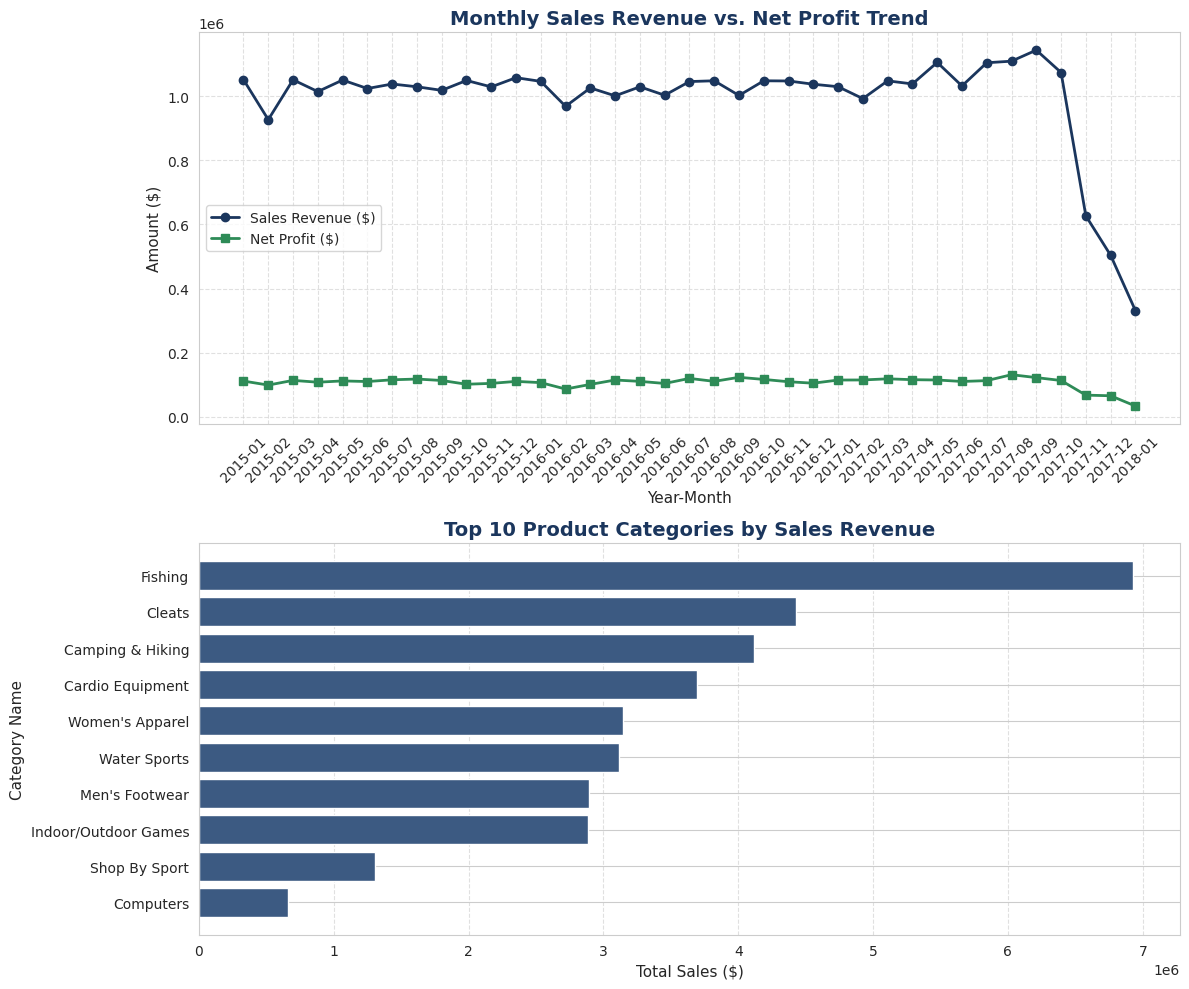


Visuals saved successfully to 'images/objective_1_sales_performance.png'.


In [14]:
# ==========================================
# OBJECTIVE 1: ANALYSE OVERALL SALES PERFORMANCE
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Ensure visualizations directory exists
import os
os.makedirs('images', exist_ok=True)

# 1. Calculate Key Sales Metrics
total_sales = df['Sales'].sum()
total_profit = df['Order Profit Per Order'].sum()
overall_profit_margin = (total_profit / total_sales) * 100
total_orders = df['Order Id'].nunique()

print("="*50)
print("OBJECTIVE 1: EXECUTIVE SUMMARY METRICS")
print("="*50)
print(f"Total Sales Revenue      : ${total_sales:,.2f}")
print(f"Total Net Profit         : ${total_profit:,.2f}")
print(f"Overall Profit Margin    : {overall_profit_margin:.2f}%")
print(f"Total Unique Orders      : {total_orders:,}")

# 2. Monthly Trend Aggregation
monthly_perf = df.groupby('YearMonth').agg(
    Monthly_Sales=('Sales', 'sum'),
    Monthly_Profit=('Order Profit Per Order', 'sum')
).reset_index()

# 3. Top Categories Aggregation
top_categories = df.groupby('Category Name').agg(
    Total_Sales=('Sales', 'sum')
).sort_values(by='Total_Sales', ascending=False).head(10).reset_index()

# ==========================================
# GENERATE RECOMMENDED VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(2, 1, figsize=(12, 10))

# Visual A: Line Chart - Monthly Sales Revenue vs Net Profit
axes[0].plot(monthly_perf['YearMonth'], monthly_perf['Monthly_Sales'], marker='o', color='#1B365D', linewidth=2, label='Sales Revenue ($)')
axes[0].plot(monthly_perf['YearMonth'], monthly_perf['Monthly_Profit'], marker='s', color='#2E8B57', linewidth=2, label='Net Profit ($)')
axes[0].set_title('Monthly Sales Revenue vs. Net Profit Trend', fontsize=14, fontweight='bold', color='#1B365D')
axes[0].set_xlabel('Year-Month', fontsize=11)
axes[0].set_ylabel('Amount ($)', fontsize=11)
axes[0].tick_params(axis='x', rotation=45)
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Visual B: Bar Chart - Top 10 Product Categories by Sales
top_categories_sorted = top_categories.sort_values(by='Total_Sales', ascending=True)
axes[1].barh(top_categories_sorted['Category Name'], top_categories_sorted['Total_Sales'], color='#3C5A82')
axes[1].set_title('Top 10 Product Categories by Sales Revenue', fontsize=14, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Total Sales ($)', fontsize=11)
axes[1].set_ylabel('Category Name', fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('images/objective_1_sales_performance.png', dpi=300)
plt.show()

print("\nVisuals saved successfully to 'images/objective_1_sales_performance.png'.")

OBJECTIVE 2: SHIPPING MODE PERFORMANCE SUMMARY
 Shipping Mode  Avg_Actual_Days  Avg_Scheduled_Days  Avg_Delay_Variance  Late_Risk_Rate
   First Class         2.000000                 1.0            1.000000       95.267388
      Same Day         0.483618                 0.0            0.483618       46.149538
  Second Class         4.001565                 2.0            2.001565       76.717796
Standard Class         3.996898                 4.0           -0.003102       38.131930


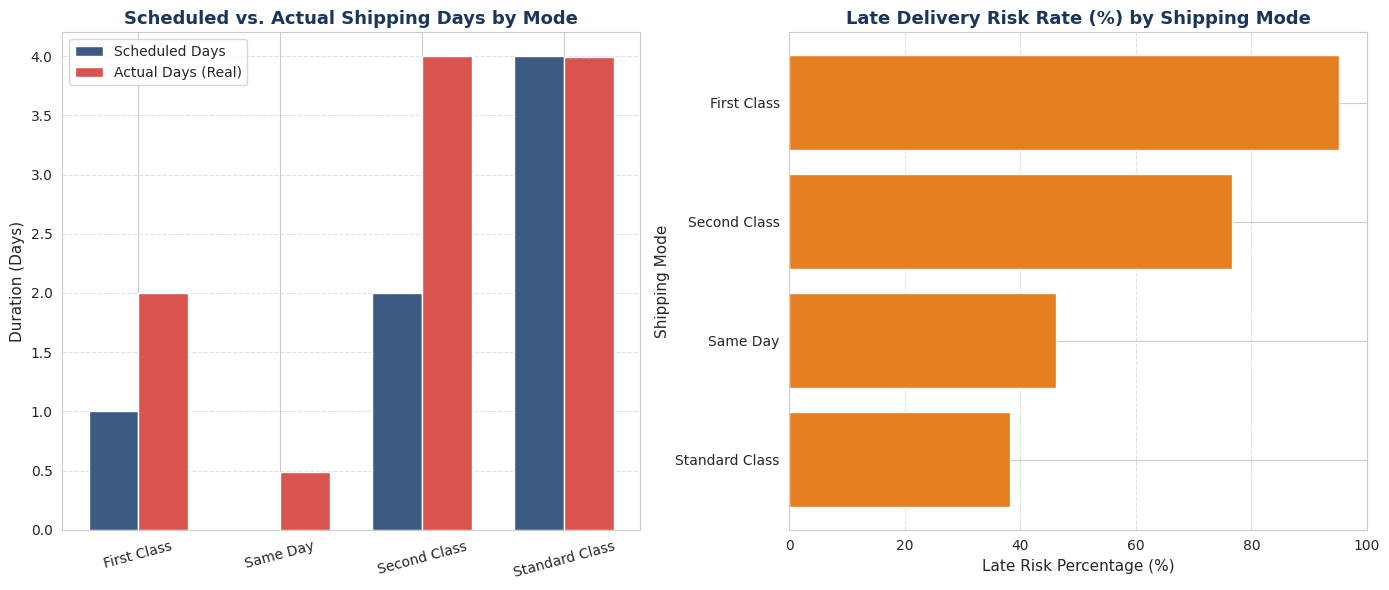


Visuals saved successfully to 'images/objective_2_shipping_performance.png'.


In [15]:
# ==========================================
# OBJECTIVE 2: SHIPPING MODE PERFORMANCE & FULFILLMENT EFFICIENCY
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Ensure visualizations directory exists
import os
os.makedirs('images', exist_ok=True)

# 1. Prepare Shipping & Orders Data
df_ship = orders.merge(shipping, on='Shipment_Id', how='left')
df_ship['Delay_Days'] = df_ship['Days for shipping (real)'] - df_ship['Days for shipment (scheduled)']

# 2. Aggregate Metrics by Shipping Mode
shipping_perf = df_ship.groupby('Shipping Mode').agg(
    Avg_Actual_Days=('Days for shipping (real)', 'mean'),
    Avg_Scheduled_Days=('Days for shipment (scheduled)', 'mean'),
    Avg_Delay_Variance=('Delay_Days', 'mean'),
    Late_Risk_Rate=('Late_delivery_risk', lambda x: x.mean() * 100)
).reset_index()

print("="*60)
print("OBJECTIVE 2: SHIPPING MODE PERFORMANCE SUMMARY")
print("="*60)
print(shipping_perf.to_string(index=False))

# ==========================================
# GENERATE RECOMMENDED VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Visual A: Grouped Bar Chart - Actual vs. Scheduled Shipping Days
x = np.arange(len(shipping_perf['Shipping Mode']))
width = 0.35

axes[0].bar(x - width/2, shipping_perf['Avg_Scheduled_Days'], width, label='Scheduled Days', color='#3C5A82')
axes[0].bar(x + width/2, shipping_perf['Avg_Actual_Days'], width, label='Actual Days (Real)', color='#D9534F')
axes[0].set_title('Scheduled vs. Actual Shipping Days by Mode', fontsize=13, fontweight='bold', color='#1B365D')
axes[0].set_xticks(x)
axes[0].set_xticklabels(shipping_perf['Shipping Mode'], rotation=15)
axes[0].set_ylabel('Duration (Days)', fontsize=11)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# Visual B: Horizontal Bar Chart - Late Delivery Risk / Variance Rate
shipping_perf_sorted = shipping_perf.sort_values(by='Late_Risk_Rate', ascending=True)
axes[1].barh(shipping_perf_sorted['Shipping Mode'], shipping_perf_sorted['Late_Risk_Rate'], color='#E67E22')
axes[1].set_title('Late Delivery Risk Rate (%) by Shipping Mode', fontsize=13, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Late Risk Percentage (%)', fontsize=11)
axes[1].set_ylabel('Shipping Mode', fontsize=11)
axes[1].grid(axis='x', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('images/objective_2_shipping_performance.png', dpi=300)
plt.show()

print("\nVisuals saved successfully to 'images/objective_2_shipping_performance.png'.")

DEPARTMENT PROFITABILITY SUMMARY
   Department Name  Total_Sales  Total_Profit  Avg_Discount_Rate  Profit_Margin_%
           Apparel 7.976255e+06  8.818829e+05           0.101656        11.056353
         Book Shop 1.258740e+04  8.830100e+02           0.102296         7.015031
        Discs Shop 2.288877e+05  2.419312e+04           0.101826        10.569863
          Fan Shop 1.711387e+07  1.834155e+06           0.101647        10.717362
           Fitness 3.970509e+05  4.653806e+04           0.101593        11.720931
          Footwear 4.006499e+06  4.102225e+05           0.101661        10.238927
              Golf 4.609028e+06  4.975236e+05           0.101577        10.794544
Health and Beauty  1.060805e+05  9.493630e+03           0.101354         8.949460
          Outdoors 1.253351e+06  1.452515e+05           0.102148        11.589045
          Pet Shop 4.152480e+04  3.589260e+03           0.101585         8.643654
        Technology 1.039599e+06  1.131700e+05           0.101816 

/tmp/ipykernel_613/3002731284.py:51: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  discount_impact = df.groupby('Discount_Bin')['Order Profit Per Order'].mean().reset_index()


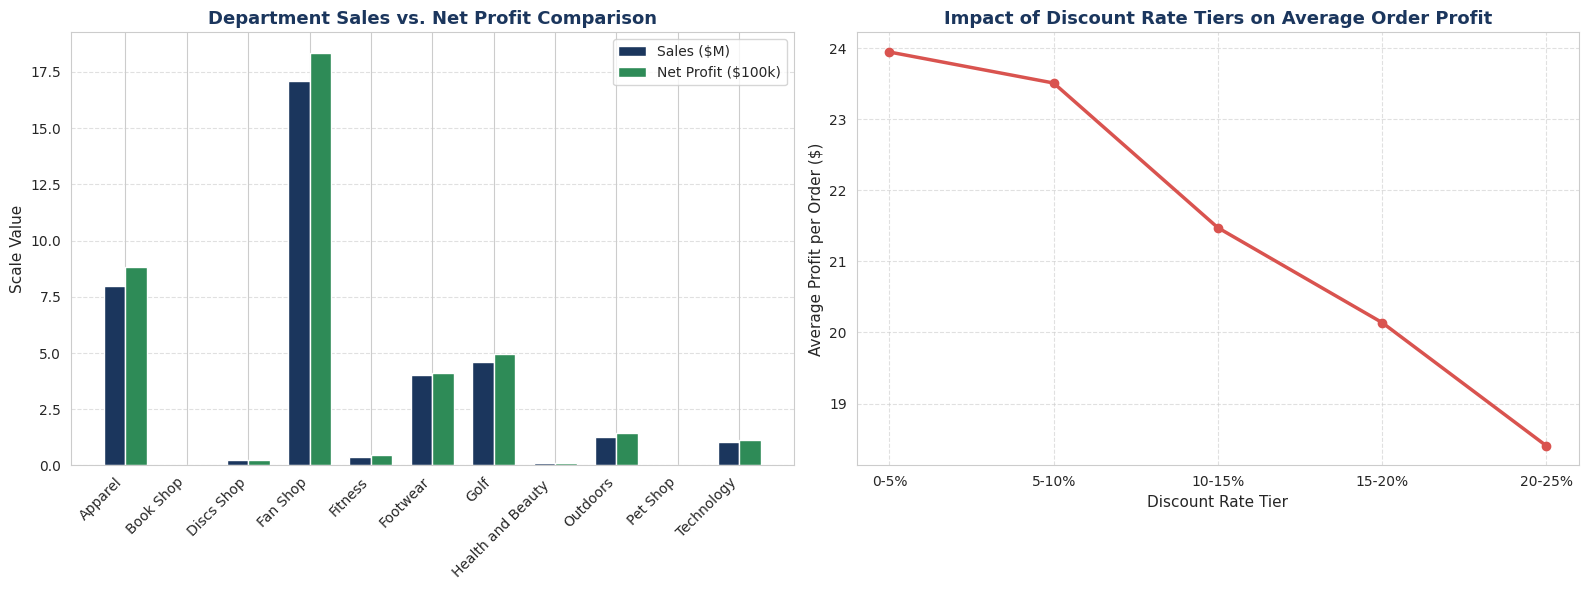


Visuals saved successfully to 'images/objective_3_profitability.png'.


In [16]:
# ==========================================
# OBJECTIVE 3: PRODUCT, CATEGORY & DEPARTMENT PROFITABILITY
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Ensure visualizations directory exists
import os
os.makedirs('images', exist_ok=True)

# 1. Department Profitability Aggregation
dept_perf = df.groupby('Department Name').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Order Profit Per Order', 'sum'),
    Avg_Discount_Rate=('Order Item Discount Rate', 'mean')
).reset_index()
dept_perf['Profit_Margin_%'] = (dept_perf['Total_Profit'] / dept_perf['Total_Sales']) * 100

print("="*60)
print("DEPARTMENT PROFITABILITY SUMMARY")
print("="*60)
print(dept_perf.to_string(index=False))

# ==========================================
# GENERATE RECOMMENDED VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Visual A: Clustered Bar Chart - Department Sales vs. Net Profit
x = np.arange(len(dept_perf['Department Name']))
width = 0.35

sales_scaled = dept_perf['Total_Sales'] / 1e6  # in Millions
profit_scaled = dept_perf['Total_Profit'] / 1e5 # in 100k for scaling

axes[0].bar(x - width/2, sales_scaled, width, label='Sales ($M)', color='#1B365D')
axes[0].bar(x + width/2, profit_scaled, width, label='Net Profit ($100k)', color='#2E8B57')
axes[0].set_title('Department Sales vs. Net Profit Comparison', fontsize=13, fontweight='bold', color='#1B365D')
axes[0].set_xticks(x)
axes[0].set_xticklabels(dept_perf['Department Name'], rotation=45, ha='right')
axes[0].set_ylabel('Scale Value', fontsize=11)
axes[0].legend()
axes[0].grid(axis='y', linestyle='--', alpha=0.6)

# Visual B: Scatter / Line Plot - Discount Impact on Profit Margin
# Group by discount rate bins to show margin erosion
df['Discount_Bin'] = pd.cut(df['Order Item Discount Rate'], bins=5, labels=['0-5%', '5-10%', '10-15%', '15-20%', '20-25%'])
discount_impact = df.groupby('Discount_Bin')['Order Profit Per Order'].mean().reset_index()

axes[1].plot(discount_impact['Discount_Bin'], discount_impact['Order Profit Per Order'], marker='o', color='#D9534F', linewidth=2.5)
axes[1].set_title('Impact of Discount Rate Tiers on Average Order Profit', fontsize=13, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Discount Rate Tier', fontsize=11)
axes[1].set_ylabel('Average Profit per Order ($)', fontsize=11)
axes[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('images/objective_3_profitability.png', dpi=300)
plt.show()

print("\nVisuals saved successfully to 'images/objective_3_profitability.png'.")

SHIPPING MODE PROFITABILITY & COST EFFICIENCY
 Shipping Mode  Total_Sales  Total_Profit  Avg_Discount_Rate  Profit_Margin_%
   First Class 5.674370e+06  6.431219e+05           0.101007        11.333804
      Same Day 1.942529e+06  2.030184e+05           0.102245        10.451246
  Second Class 7.145445e+06  7.503082e+05           0.102117        10.500510
Standard Class 2.202239e+07  2.370454e+06           0.101640        10.763837

PREDICTIVE MODEL EVALUATION (GRADIENT BOOSTING)
Accuracy:  0.6878
Precision: 0.6391
Recall:    0.8625
F1-Score:  0.7342
ROC-AUC:   0.7409


/tmp/ipykernel_613/2372365941.py:61: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=shipping_profit, x='Shipping Mode', y='Profit_Margin_%', palette='Blues_d')


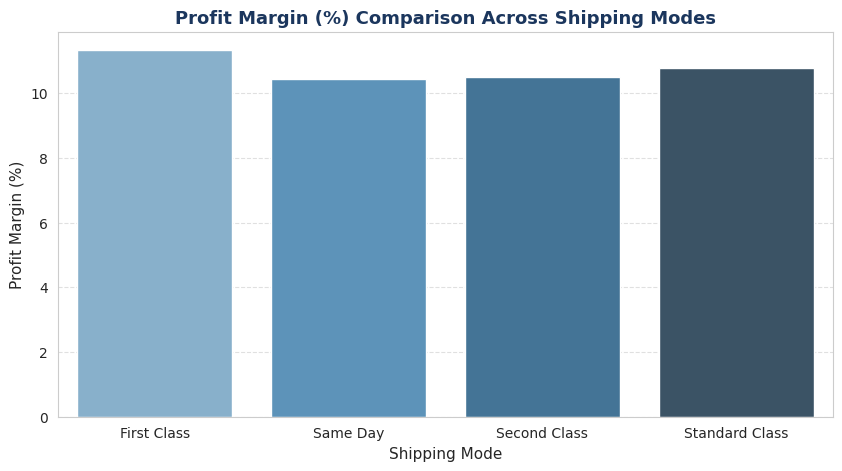


Visual saved to 'images/objective_4_shipping_profitability.png'.


In [17]:
# ==========================================
# OBJECTIVE 4: SHIPPING MODE PROFITABILITY & PREDICTIVE MODELING
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# 1. Descriptive Analysis: Profitability by Shipping Mode
shipping_profit = df.groupby('Shipping Mode').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Order Profit Per Order', 'sum'),
    Avg_Discount_Rate=('Order Item Discount Rate', 'mean')
).reset_index()
shipping_profit['Profit_Margin_%'] = (shipping_profit['Total_Profit'] / shipping_profit['Total_Sales']) * 100

print("="*60)
print("SHIPPING MODE PROFITABILITY & COST EFFICIENCY")
print("="*60)
print(shipping_profit.to_string(index=False))

# 2. Predictive Modeling: High-Margin Shipment Classification
# Define target: 1 if profit is above median, 0 otherwise
df['Target'] = (df['Order Profit Per Order'] > df['Order Profit Per Order'].median()).astype(int)

features = ['Shipping Mode', 'Order Item Discount Rate', 'Product Price', 'Order Item Quantity', 'Category Name', 'Department Name', 'Type', 'Market', 'Order Region']
ml_df = df[features + ['Target']].dropna()
ml_df_encoded = pd.get_dummies(ml_df, drop_first=True)

X = ml_df_encoded.drop(columns=['Target'])
y = ml_df_encoded['Target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

gb = GradientBoostingClassifier(n_estimators=50, random_state=42)
gb.fit(X_train, y_train)

y_pred = gb.predict(X_test)
y_prob = gb.predict_proba(X_test)[:, 1]

print("\n" + "="*60)
print("PREDICTIVE MODEL EVALUATION (GRADIENT BOOSTING)")
print("="*60)
print(f"Accuracy:  {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision: {precision_score(y_test, y_pred):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred):.4f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, y_prob):.4f}")

# ==========================================
# VISUALIZATION FOR OBJECTIVE 4
# ==========================================
import os
os.makedirs('images', exist_ok=True)

plt.figure(figsize=(10, 5))
sns.barplot(data=shipping_profit, x='Shipping Mode', y='Profit_Margin_%', palette='Blues_d')
plt.title('Profit Margin (%) Comparison Across Shipping Modes', fontsize=13, fontweight='bold', color='#1B365D')
plt.xlabel('Shipping Mode', fontsize=11)
plt.ylabel('Profit Margin (%)', fontsize=11)
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.savefig('images/objective_4_shipping_profitability.png', dpi=300)
plt.show()

print("\nVisual saved to 'images/objective_4_shipping_profitability.png'.")

CUSTOMER SEGMENT PERFORMANCE SUMMARY
Customer Segment  Total_Sales  Total_Profit  Total_Orders  Profit_Margin_%
        Consumer 1.909579e+07  2.073488e+06         34119        10.858350
       Corporate 1.116841e+07  1.202575e+06         19856        10.767650
     Home Office 6.520538e+06  6.908403e+05         11777        10.594836

SHIPPING PREFERENCES BY SEGMENT (%)
Shipping Mode     First Class  Same Day  Second Class  Standard Class
Customer Segment                                                     
Consumer            15.407897  5.505647     19.247305       59.839151
Corporate           15.116173  5.429922     19.985764       59.468141
Home Office         15.903308  5.008378     19.453237       59.635077


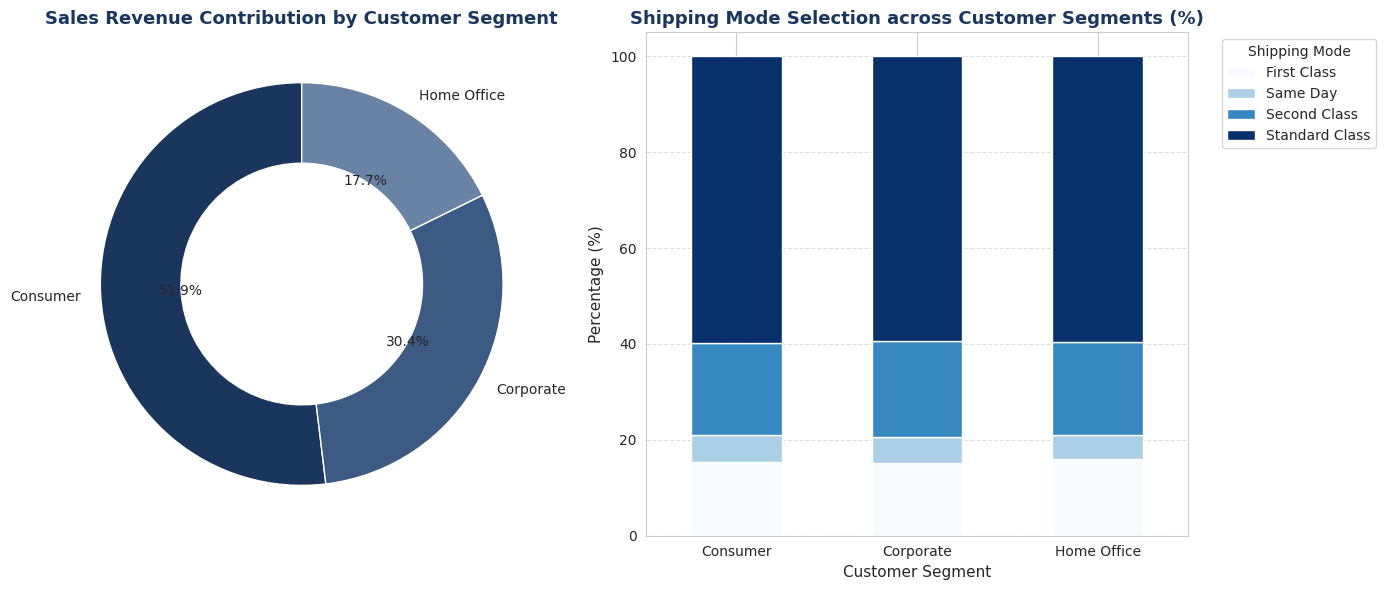


Visuals saved successfully to 'images/objective_5_customer_segments.png'.


In [18]:
# ==========================================
# OBJECTIVE 5: CUSTOMER SEGMENT PERFORMANCE & PURCHASING PATTERNS
# ==========================================

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# Ensure visualizations directory exists
import os
os.makedirs('images', exist_ok=True)

# 1. Customer Segment Aggregation
segment_perf = df.groupby('Customer Segment').agg(
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Order Profit Per Order', 'sum'),
    Total_Orders=('Order Id', 'nunique')
).reset_index()
segment_perf['Profit_Margin_%'] = (segment_perf['Total_Profit'] / segment_perf['Total_Sales']) * 100

print("="*60)
print("CUSTOMER SEGMENT PERFORMANCE SUMMARY")
print("="*60)
print(segment_perf.to_string(index=False))

# 2. Shipping Preferences Crosstab (%)
shipping_pref = pd.crosstab(df['Customer Segment'], df['Shipping Mode'], normalize='index') * 100
print("\n" + "="*60)
print("SHIPPING PREFERENCES BY SEGMENT (%)")
print("="*60)
print(shipping_pref)

# ==========================================
# GENERATE RECOMMENDED VISUALIZATIONS
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Visual A: Donut Chart - Sales Revenue Contribution by Customer Segment
colors = ['#1B365D', '#3C5A82', '#6883A3']
axes[0].pie(segment_perf['Total_Sales'], labels=segment_perf['Customer Segment'], autopct='%1.1f%%',
            colors=colors, startangle=90, wedgeprops=dict(width=0.4, edgecolor='w'))
axes[0].set_title('Sales Revenue Contribution by Customer Segment', fontsize=13, fontweight='bold', color='#1B365D')

# Visual B: Stacked Bar Chart - Shipping Mode Preferences across Segments
shipping_pref.plot(kind='bar', stacked=True, ax=axes[1], colormap='Blues')
axes[1].set_title('Shipping Mode Selection across Customer Segments (%)', fontsize=13, fontweight='bold', color='#1B365D')
axes[1].set_xlabel('Customer Segment', fontsize=11)
axes[1].set_ylabel('Percentage (%)', fontsize=11)
axes[1].legend(title='Shipping Mode', bbox_to_anchor=(1.05, 1), loc='upper left')
axes[1].tick_params(axis='x', rotation=0)
axes[1].grid(axis='y', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.savefig('images/objective_5_customer_segments.png', dpi=300)
plt.show()

print("\nVisuals saved successfully to 'images/objective_5_customer_segments.png'.")